[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pachterlab/OP_2025_2/blob/scope-future/analysis_scripts/Warp_Interpolation.ipynb)

# Warp interpolation: the bicubic grid ripple and `WARP_INTERP`

accumap's warp stage moves beads with a smooth displacement field stored on a regular control grid (400, 200 and 100 um levels
in large-array mode). Between grid nodes the field is interpolated. The default, `cm.WARP_INTERP = "bicubic"`, uses torch's
`grid_sample` bicubic mode: cubic convolution with parameter a = -0.75. That kernel does **not** reproduce a linear field: a
uniform stretch comes out as a stretch that ripples at the grid period. On Hu et al.'s 1.2 cm array (H4_2) every accumap layout
carries a faint axis-aligned density ripple at the 400 um level's node spacing (~392 um), and two runs from different starts
differ by a moire pattern of stripes.

`cm.WARP_INTERP = "catmull-rom"` (a = -0.5, same 4 x 4 support and cost) reproduces linear and quadratic fields exactly. This
notebook shows:

1. the ripple on a known warp (no data needed, CPU only);
2. that Catmull-Rom is a drop-in option in a reconstruction of a simulated array with known bead positions;
3. the measurements on real arrays that decided the default.

In [1]:
# Colab only: clone the repository (scope-future branch) and install accumap; skipped when run locally
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.exists("/content/OP_2025_2"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", "scope-future", "https://github.com/pachterlab/OP_2025_2.git", "/content/OP_2025_2"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "/content/OP_2025_2", "numba"], check=True)
if "google.colab" in sys.modules:
    os.chdir("/content/OP_2025_2/analysis_scripts")

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import accumap
import accumap.count_model as cm
import accumap.multilevel as ml

## 1. A uniform stretch through each interpolation

Control grid: 400 um spacing over 12 mm, as the coarsest warp level on a 1.2 cm array. The nodes hold an exactly linear field,
a 1% stretch along x plus a 1% shear (displacement u = 0.01 x + 0.01 y). A correct interpolation returns that field everywhere,
so its derivative, the local stretch du/dx, should be 0.01 at every point. `cm._warp_sample` is the function accumap uses to
evaluate the warp; it takes the interpolation as an argument.

bicubic      displacement error 0.192 um, local stretch 0.750..1.498% (true 1%)
catmull-rom  displacement error 0.000 um, local stretch 1.000..1.000% (true 1%)


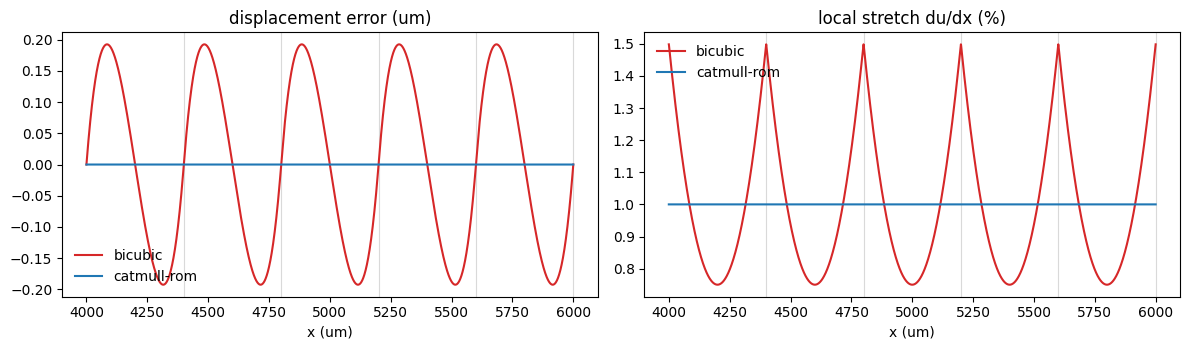

In [3]:
L, spacing = 12000.0, 400.0
n = int(np.ceil(L / spacing)) + 1
lo = torch.tensor([0.0, 0.0], dtype=torch.float64); hi = torch.tensor([L, L], dtype=torch.float64)
g = torch.linspace(0, L, n, dtype=torch.float64)
GX, GY = torch.meshgrid(g, g, indexing="xy")
D = torch.stack([0.01 * GX + 0.01 * GY, torch.zeros_like(GX)])[None]          # nodal values of an exactly linear field

x = torch.linspace(4000, 6000, 4001, dtype=torch.float64)                      # a 2 mm transect along x, away from the edges
P = torch.stack([x, torch.full_like(x, 5000.0)], 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for interp, col in (("bicubic", "tab:red"), ("catmull-rom", "tab:blue")):
    u = cm._warp_sample(D, P, lo, hi, interp=interp)[:, 0].numpy()
    err = u - (0.01 * x.numpy() + 0.01 * 5000.0)
    stretch = np.gradient(u, x.numpy())
    print(f"{interp:12s} displacement error {np.abs(err).max():.3f} um, local stretch {100 * stretch.min():.3f}..{100 * stretch.max():.3f}% (true 1%)")
    ax[0].plot(x, err, color=col, label=interp); ax[1].plot(x, 100 * stretch, color=col, label=interp)
for a, t in zip(ax, ("displacement error (um)", "local stretch du/dx (%)")):
    a.set_xlabel("x (um)"); a.set_title(t); a.legend(frameon=False)
    for k in range(int(4000 // spacing) + 1, int(6000 // spacing) + 1):
        a.axvline(k * L / (n - 1), color="0.85", lw=0.8, zorder=0)
plt.tight_layout(); plt.show()

Grey lines mark the control nodes. The bicubic displacement error is small (under half a micron), but the local stretch swings
between 0.75% and 1.5% inside every cell. Bead density follows the local area change, so beads come out slightly bunched and
spread in a pattern locked to the grid.

## 2. The ripple in two dimensions

The local area change of the warped layout is the Jacobian determinant of x -> x + u(x). Here it is on a fine grid for a 3%
stretch along x and a 2% shear, again an exactly linear field at the nodes. A correct interpolation gives a constant.

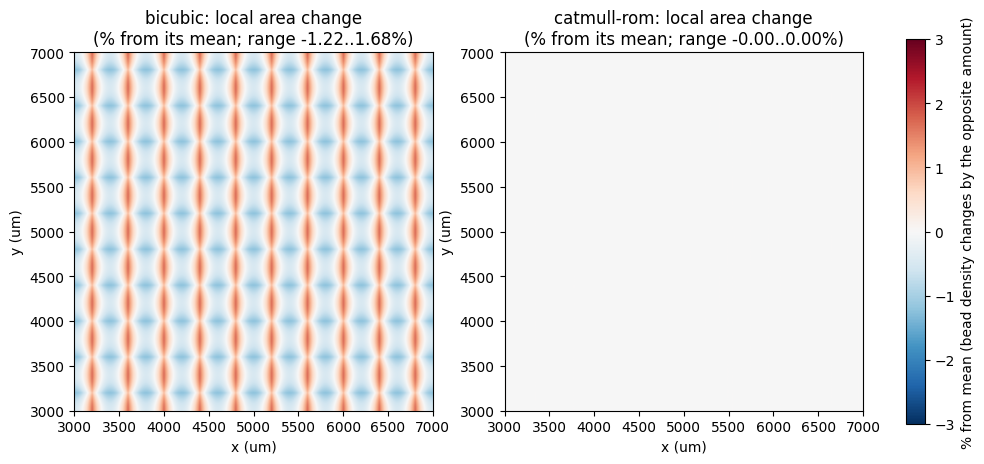

In [4]:
def jacobian_det(D, lo, hi, interp, x0=3000, x1=7000, h=5.0):
    xs = torch.arange(x0, x1, h, dtype=torch.float64)
    XX, YY = torch.meshgrid(xs, xs, indexing="xy")
    P = torch.stack([XX.reshape(-1), YY.reshape(-1)], 1)
    ex = torch.tensor([h / 2, 0.0], dtype=torch.float64); ey = torch.tensor([0.0, h / 2], dtype=torch.float64)
    dx = (cm._warp_sample(D, P + ex, lo, hi, interp=interp) - cm._warp_sample(D, P - ex, lo, hi, interp=interp)) / h
    dy = (cm._warp_sample(D, P + ey, lo, hi, interp=interp) - cm._warp_sample(D, P - ey, lo, hi, interp=interp)) / h
    det = (1 + dx[:, 0]) * (1 + dy[:, 1]) - dx[:, 1] * dy[:, 0]
    return det.reshape(XX.shape).numpy(), (x0, x1)

D2 = torch.stack([0.03 * GX + 0.02 * GY, 0.01 * GX - 0.01 * GY])[None]
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, interp in zip(ax, ("bicubic", "catmull-rom")):
    J, (x0, x1) = jacobian_det(D2, lo, hi, interp)
    dev = 100 * (J / J.mean() - 1)
    im = a.imshow(dev, origin="lower", extent=[x0, x1, x0, x1], cmap="RdBu_r", vmin=-3, vmax=3)
    a.set_title(f"{interp}: local area change\n(% from its mean; range {dev.min():.2f}..{dev.max():.2f}%)")
    a.set_xlabel("x (um)"); a.set_ylabel("y (um)")
fig.colorbar(im, ax=ax, fraction=0.025, label="% from mean (bead density changes by the opposite amount)")
plt.show()

With bicubic interpolation a smooth, uniform deformation becomes a checkerboard of +-1-2% area changes at the 400 um node
spacing. Catmull-Rom gives the constant it should. In accumap the warp always carries some large-scale stretch (correcting the
starting layout), and every warp stage and every round adds a ripple in the same place, because each run's grid is anchored to
its own layout's extent. Two runs from different starts have slightly rotated grids, so the difference between them shows the
moire stripes seen on H4_2.

## 3. In a reconstruction: a drop-in option

A small simulated shared-bead array (3 x 1.5 mm, true positions known, counts from the Poisson model fitted to SCOPE's circular
array), multilevel start, then accumap with each interpolation. Errors are measured after a similarity alignment refit on the
best-placed 90% of beads. On an array this small the ripple is far below the bead-count noise, so this checks only that the
option is a safe drop-in. The multilevel start takes most of the time (about 20 min on bio's CPUs; the two reconstructions take about a minute each on one GPU).

In [5]:
X, C = accumap.simulate_shared_array(3000.0, 1500.0, seed=1)
footprint = np.array([[-1500, -750], [1500, -750], [1500, 750], [-1500, 750]], float)
diameter = float(np.hypot(3000, 1500))
t0 = time.time()
E, _ = accumap.multilevel_layout(C, footprint=footprint, target=1500, finest=70000, seed=0, verbose=False)
print(f"{C.shape[0]:,} beads, {C.nnz:,} nonzero pairs; multilevel start {time.time() - t0:.0f} s")

def robust_error(Y, X, keep=0.9):
    Y = np.asarray(Y, float); A, T = accumap.similarity_align(Y, X); e = np.linalg.norm(A - T, axis=1)
    for _ in range(3):
        m = e <= np.quantile(e, keep); P_, Q_ = Y[m] - Y[m].mean(0), X[m] - X[m].mean(0)
        U, s, Vt = np.linalg.svd(P_.T @ Q_)
        e = np.linalg.norm((Y - Y[m].mean(0)) @ (U @ Vt) * (s.sum() / np.sum(P_ ** 2)) - (X - X[m].mean(0)), axis=1)
    return e

results = {}
for interp in ("bicubic", "catmull-rom"):
    cm.WARP_INTERP = interp
    t0 = time.time()
    R = accumap.reconstruct(C, np.asarray(E, float), diameter, shared=True, footprint=footprint, verbose=False)
    Y = np.asarray(R["receivers"], float); e = robust_error(Y, X)
    results[interp] = {"robust median (um)": np.median(e), "p90 (um)": np.percentile(e, 90),
                       "log-likelihood": cm.log_likelihood(C, Y, diameter, shared=True), "time (s)": time.time() - t0}
cm.WARP_INTERP = "bicubic"                     # back to the default
import pandas as pd
pd.DataFrame(results).T.round(2)

/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/coakes/miniconda3/envs/accumap_fig/lib/python3.11/site-packages/torch/_inductor/compile_fx.py:167: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(


7,696 beads, 2,120,340 nonzero pairs; multilevel start 1140 s


,robust median (um),p90 (um),log-likelihood,time (s)
bicubic,12.89,24.24,1023644.0,62.84
catmull-rom,13.96,24.77,1023174.0,72.17


The two interpolations land within about 1 um of each other, in either direction from run to run. An earlier run of exactly this
case gave bicubic 15.05 um and Catmull-Rom 14.06 um (p90 23.8 / 22.5), the opposite order to the table above. Across four
simulations (shared 3 x 1.5 mm seeds 1 and 2, calibrated distinct-bead seeds 0 and 1) the median differences were -1.0, -0.0,
+0.6 and -0.2 um (Catmull-Rom minus bicubic), with log-likelihoods within 0.01%. On simulations of this size the choice of
interpolation is within run-to-run noise.

## 4. Real arrays, and why bicubic stays the default

Measured on bio (two 8 GB GPUs) with the same accumap settings; the real data are not part of this repository.

| Array | Measure | bicubic | catmull-rom |
|---|---|---|---|
| Hu H4_2 (1.2 cm, 878k receivers x 207k senders) | density ripple at ~392 um, 1 round | 0.9-1.7% | 0.2-0.6% (no peak) |
| | density ripple, 2 rounds | 2.5-3.5% | 0.3-0.6% (no peak) |
| | log-likelihood, round 1, starts 0 / 1 (x1e7) | -25.426 / -25.423 | -25.429 / -25.422 |
| SCOPE eye chart (1.44M shared beads), 2 rounds | log-likelihood (x1e9) | -3.4117 / -3.4084 (2 runs) | -3.4185 |
| | AUC against the chart image, without the E | .873 / .870 | .865 |
| Simulations (shared 3 x 1.5 mm, calibrated distinct-bead; 2 seeds each) | median error | within run-to-run noise | within run-to-run noise |

The ripple is about 1.5 um of displacement and the counts barely see it (equal log-likelihoods on H4_2). On the eye chart the one
Catmull-Rom run came out slightly worse, so the default stays bicubic. Use Catmull-Rom when the layout's fine-scale density
matters, for example when comparing runs or measuring local density:

```python
import accumap.count_model as cm
cm.WARP_INTERP = "catmull-rom"
```